<center><h1>Zhan_Jenna_HW4</h1></center>
<br>
<br>

Name: Jenna Zhan
<br>
Github Username: jenna-zhan
<br>
USC ID: 2477604908

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB

Get the AReM Data Set

In [2]:
arem_path = "../data/AReM"
arem = os.listdir(arem_path)
print(arem)

['bendingType.pdf', '.DS_Store', 'bending1', 'walking', 'sensorsPlacement.pdf', 'bending2', 'standing', 'sitting', 'lying', 'cycling']


### (b) Splitting Data

In [3]:
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

train_set = []
test_set = []

for activity in activities:
    activity_path = os.path.join(arem_path, activity)
    dataset = os.listdir(activity_path)

    print(activity, len(dataset))

bending1 7
bending2 6
cycling 15
lying 15
sitting 15
standing 15
walking 15


In [4]:
for activity in activities:
    activity_path = os.path.join(arem_path, activity)
    
    dataset = [
        file for file in os.listdir(activity_path)
        if file.startswith("dataset") and file.endswith(".csv")
    ]

    for file in dataset:
        file_num = int(
            file.replace("dataset", "").replace(".csv", "")
        )

        file_path = os.path.join(activity_path, file)

        if activity in ["bending1", "bending2"]:
            if file_num in [1, 2]:
                test_set.append(file_path)
            else:
                train_set.append(file_path)
        else:
            if file_num in [1, 2, 3]:
                test_set.append(file_path)
            else:
                train_set.append(file_path)

print("training instances:", len(train_set))
print("test instances:", len(test_set))
print("total instances:", len(train_set) + len(test_set))

training instances: 69
test instances: 19
total instances: 88


### (c) Feature Extraction

In [5]:
time_series = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [6]:
all_files = train_set + test_set

print(len(all_files))

88


In [7]:
def extract_features(file_path):

    if "bending2/dataset4.csv" in file_path:
        data = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            names=[
                "time",
                "avg_rss12",
                "var_rss12",
                "avg_rss13",
                "var_rss13",
                "avg_rss23",
                "var_rss23"
            ]
        )
    else:
        data = pd.read_csv(
            file_path,
            skiprows=4,
            usecols=range(7)
        )

    features = {}

    for i, column in enumerate(time_series, start=1):
        ts = data[column]

        features[f"min{i}"] = ts.min()
        features[f"max{i}"] = ts.max()
        features[f"mean{i}"] = ts.mean()
        features[f"median{i}"] = ts.median()
        features[f"std{i}"] = ts.std()
        features[f"1st_quart{i}"] = ts.quantile(0.25)
        features[f"3rd_quart{i}"] = ts.quantile(0.75)

    return features

In [8]:
for file in all_files:
    try:
        extract_features(file)
    except Exception as e:
        print("problem file:", file)
        print("error:", e)

In [9]:
problem_files = [
    "../data/AReM/cycling/dataset14.csv",
    "../data/AReM/cycling/dataset9.csv"
]

for file in problem_files:
    print("\n", file)

    with open(file, "r") as f:
        lines = f.readlines()

    for line in lines[-5:]:
        print(line.strip())


 ../data/AReM/cycling/dataset14.csv
118750,35.00,3.00,21.50,2.50,15.75,7.76
119000,40.25,2.49,19.75,3.27,21.50,2.29
119250,41.50,0.87,12.75,4.44,17.75,2.38
119500,33.33,6.18,15.50,3.77,17.00,4.32
119750,34.00,2.12,24.50,1.80,22.25,2.59,

 ../data/AReM/cycling/dataset9.csv
118750,41.75,1.79,11.00,6.00,16.67,2.49
119000,36.33,0.47,16.00,3.16,20.33,1.70
119250,31.50,1.50,21.00,0.00,12.25,7.12
119500,34.25,6.38,12.67,2.49,15.25,4.21
119750,38.33,0.94,15.25,2.17,20.33,1.25,


In [10]:
all_features = []

for file in all_files:
    features = extract_features(file)
    all_features.append(features)

feature_df = pd.DataFrame(all_features)

print(feature_df.shape)
feature_df.head()

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83
1,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
4,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94


In [11]:
print(feature_df.isna().sum().sum())

0


In [12]:
feature_table = feature_df.copy()
feature_table.insert(0, "instance", range(1, 89))

feature_table

,instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
1,2,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
2,3,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
3,4,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
4,5,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
84,85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
85,86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425
86,87,12.50,45.00,33.509729,34.125,4.850923,30.50,36.7500,0.0,13.05,...,3.133564,14.6275,18.750,0.0,8.96,3.378479,3.085,1.787360,2.060,4.440


In [13]:
feature_std = feature_df.std()

feature_std

min1          9.569975
max1          4.394362
mean1         5.335718
median1       5.440054
std1          1.772153
1st_quart1    6.153590
3rd_quart1    5.138925
min2          0.000000
max2          5.062729
mean2         1.574164
median2       1.412244
std2          0.884105
1st_quart2    0.946386
3rd_quart2    2.125266
min3          2.956462
max3          4.875137
mean3         4.008380
median3       4.036396
std3          0.946710
1st_quart3    4.220658
3rd_quart3    4.171628
min4          0.000000
max4          2.183625
mean4         1.166114
median4       1.145586
std4          0.458242
1st_quart4    0.843620
3rd_quart4    1.552504
min5          6.124001
max5          5.741238
mean5         5.675593
median5       5.813782
std5          1.024898
1st_quart5    6.096465
3rd_quart5    5.531720
min6          0.045838
max6          2.518921
mean6         1.154812
median6       1.086474
std6          0.517617
1st_quart6    0.758584
3rd_quart6    1.523599
dtype: float64

In [14]:
feature_df.isna().sum()[feature_df.isna().sum() > 0]

feature_df[feature_df.isna().any(axis=1)]

nan_rows = feature_df[feature_df.isna().any(axis=1)].index

for i in nan_rows:
    print("row:", i)
    print("file:", all_files[i])


In [15]:
problem_file = "../data/AReM/bending2/dataset4.csv"

with open(problem_file, "r") as f:
    lines = f.readlines()

for line in lines[:10]:
    print(line.strip())

# Task: bending2
# Frequency (Hz): 20
# Clock (millisecond): 250
# Duration (seconds): 120
# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0 32.50 0.50 0.00 0.00 19.00 1.00
250 32.50 0.50 0.00 0.00 18.50 0.50
500 32.75 0.43 1.00 0.00 18.00 0.00
750 32.50 0.50 0.00 0.00 17.50 0.50
1000 32.50 0.50 7.50 0.50 17.50 0.87


In [16]:
np.random.seed(5)

bootstrap_results = []

for column in feature_df.columns:
    values = feature_df[column].values
    bootstrap_std = []

    for i in range(1000):
        bootstrap_sample = np.random.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_std.append(
            np.std(bootstrap_sample, ddof=1)
        )

    ci_lower = np.percentile(bootstrap_std, 5)
    ci_upper = np.percentile(bootstrap_std, 95)

    bootstrap_results.append({
        "feature": column,
        "standard deviation": feature_std[column],
        "90% ci lower": ci_lower,
        "90% ci upper": ci_upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

bootstrap_df

,feature,standard deviation,90% ci lower,90% ci upper
0,min1,9.569975,8.204965,10.709391
1,max1,4.394362,3.403882,5.300683
2,mean1,5.335718,4.711753,5.892600
3,median1,5.440054,4.777375,5.988009
4,std1,1.772153,1.571347,1.935718
5,1st_quart1,6.153590,5.591167,6.629550
6,3rd_quart1,5.138925,4.344417,5.865224
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.626905,5.389798
9,mean2,1.574164,1.400806,1.709856


In [17]:
feature_types = [
    "min",
    "max",
    "mean",
    "median",
    "std",
    "1st_quart",
    "3rd_quart"
]

feature_comparison = {}

for feature in feature_types:
    columns = [f"{feature}{i}" for i in range(1, 7)]
    feature_comparison[feature] = feature_df[columns].std().mean()

feature_comparison = pd.Series(
    feature_comparison
).sort_values(ascending=False)

feature_comparison

max          4.129335
3rd_quart    3.340607
1st_quart    3.169884
median       3.155756
mean         3.152463
min          3.116046
std          0.933954
dtype: float64

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [18]:
train_labels = []

for file in train_set:
    if "bending1" in file or "bending2" in file:
        train_labels.append(1)
    else:
        train_labels.append(0)

train_features = []

for file in train_set:
    features = extract_features(file)
    train_features.append(features)

train_feature_df = pd.DataFrame(train_features)

print(train_feature_df.shape)
train_feature_df.head()

(69, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83
1,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
4,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94


In [19]:
scatter_data = train_feature_df[[
    "max1", "3rd_quart1", "mean1",
    "max2", "3rd_quart2", "mean2",
    "max6", "3rd_quart6", "mean6"
]].copy()
scatter_data["label"] = train_labels

scatter_data.head()

,max1,3rd_quart1,mean1,max2,3rd_quart2,mean2,max6,3rd_quart6,mean6,label
0,48.00,44.67,43.969125,1.50,0.50,0.413125,2.96,0.83,0.555312,1
1,48.00,45.00,43.454958,1.58,0.50,0.378083,5.26,0.87,0.679646,1
2,47.75,45.00,42.179812,3.00,1.12,0.696042,2.18,1.00,0.613521,1
3,45.75,42.75,41.678063,2.83,0.71,0.535979,1.79,0.50,0.383292,1
4,47.40,45.00,43.954500,1.70,0.50,0.426250,1.79,0.94,0.493292,1


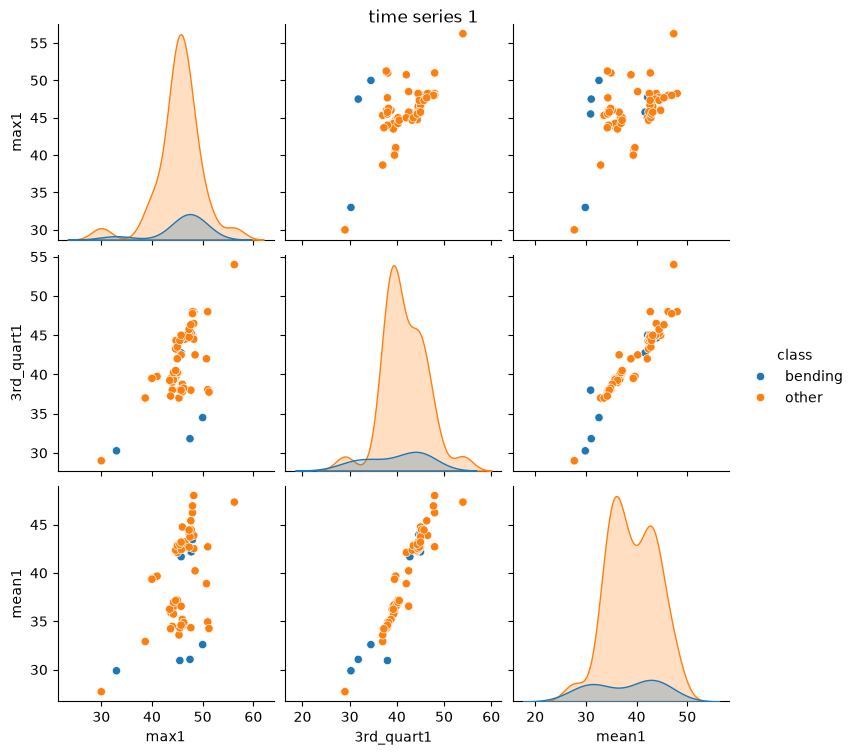

In [20]:
ts1_data = scatter_data[
    ["max1", "3rd_quart1", "mean1", "label"]
].copy()

ts1_data["class"] = ts1_data["label"].map({
    1: "bending",
    0: "other"
})

sns.pairplot(
    ts1_data,
    vars=["max1", "3rd_quart1", "mean1"],
    hue="class"
)

plt.suptitle("time series 1",y = 1)
plt.show()

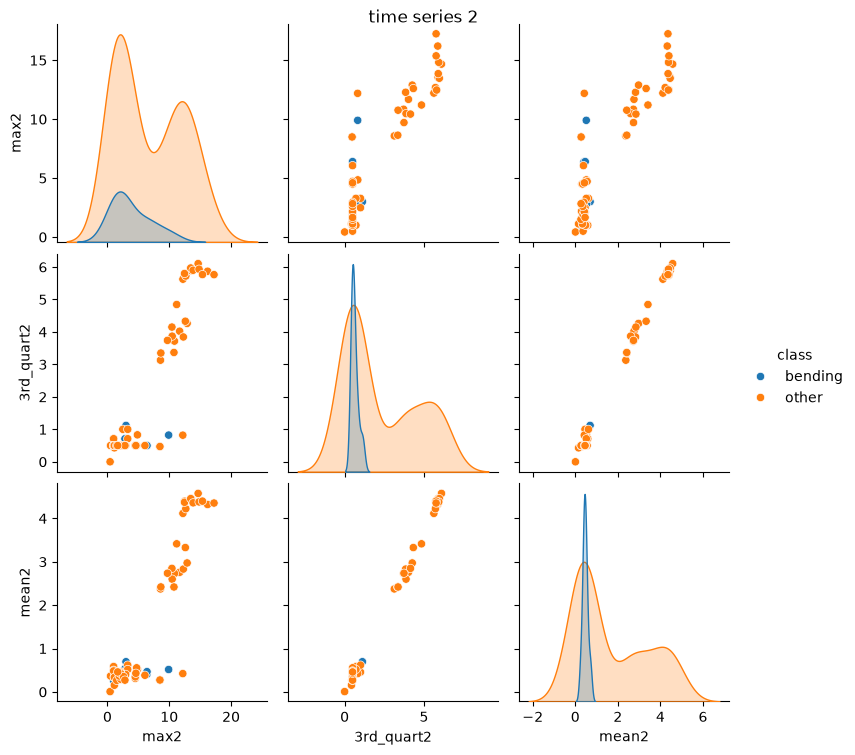

In [21]:
ts2_data = scatter_data[
    ["max2", "3rd_quart2", "mean2", "label"]
].copy()

ts2_data["class"] = ts2_data["label"].map({
    1: "bending",
    0: "other"
})

sns.pairplot(
    ts2_data,
    vars=["max2", "3rd_quart2", "mean2"],
    hue="class"
)

plt.suptitle("time series 2",y = 1)
plt.show()

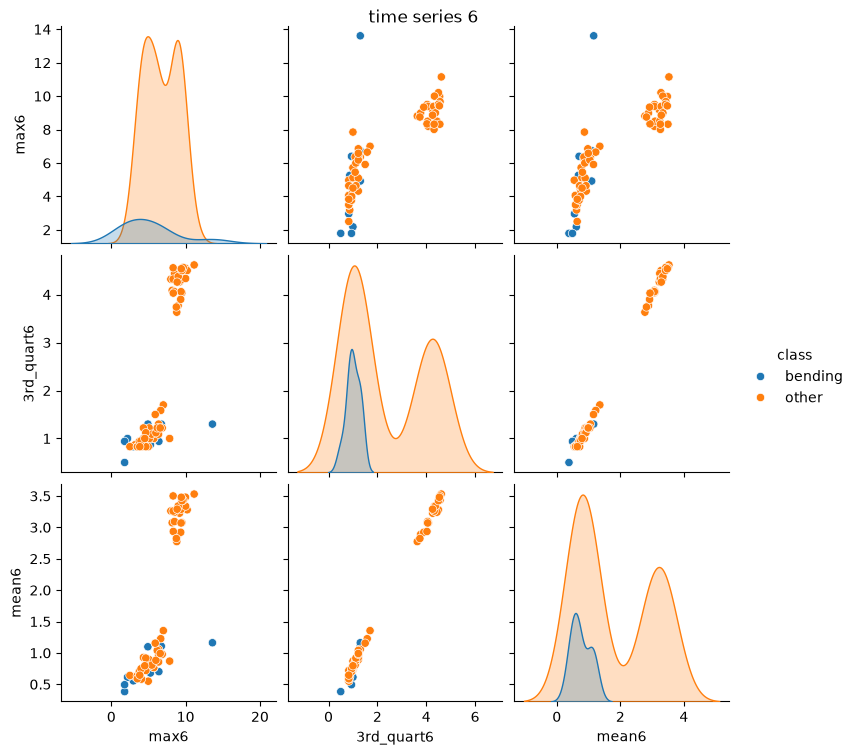

In [22]:
ts6_data = scatter_data[
    ["max6", "3rd_quart6", "mean6", "label"]
].copy()

ts6_data["class"] = ts6_data["label"].map({
    1: "bending",
    0: "other"
})

sns.pairplot(
    ts6_data,
    vars=["max6", "3rd_quart6", "mean6"],
    hue="class"
)

plt.suptitle("time series 6",y = 1)
plt.show()

#### ii. Splitted Plots

In [23]:
def extract_split_features(file_path):
    if "bending2/dataset4.csv" in file_path:
        data = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            names=[
                "time",
                "avg_rss12",
                "var_rss12",
                "avg_rss13",
                "var_rss13",
                "avg_rss23",
                "var_rss23"
            ]
        )
    else:
        data = pd.read_csv(
            file_path,
            skiprows=4,
            usecols=range(7)
        )

    features = {}

    for i, column in enumerate(time_series, start=1):
        ts = data[column]

        middle = len(ts) // 2

        part1 = ts.iloc[:middle]
        part2 = ts.iloc[middle:]

        features[f"max{i}_part1"] = part1.max()
        features[f"3rd_quart{i}_part1"] = part1.quantile(0.75)
        features[f"mean{i}_part1"] = part1.mean()

        features[f"max{i}_part2"] = part2.max()
        features[f"3rd_quart{i}_part2"] = part2.quantile(0.75)
        features[f"mean{i}_part2"] = part2.mean()

    return features

In [24]:
train_split_features = []

for file in train_set:
    features = extract_split_features(file)
    train_split_features.append(features)

train_split_feature_df = pd.DataFrame(train_split_features)

In [25]:
scatter_split_data = train_split_feature_df[[
    "max1_part1", "3rd_quart1_part1", "mean1_part1",
    "max1_part2", "3rd_quart1_part2", "mean1_part2",

    "max2_part1", "3rd_quart2_part1", "mean2_part1",
    "max2_part2", "3rd_quart2_part2", "mean2_part2",

    "max6_part1", "3rd_quart6_part1", "mean6_part1",
    "max6_part2", "3rd_quart6_part2", "mean6_part2"
]].copy()

scatter_split_data["label"] = train_labels

scatter_split_data.head()

,max1_part1,3rd_quart1_part1,mean1_part1,max1_part2,3rd_quart1_part2,mean1_part2,max2_part1,3rd_quart2_part1,mean2_part1,max2_part2,3rd_quart2_part2,mean2_part2,max6_part1,3rd_quart6_part1,mean6_part1,max6_part2,3rd_quart6_part2,mean6_part2,label
0,45.00,44.50,43.486208,48.00,44.75,44.452042,1.30,0.50,0.378667,1.50,0.5000,0.447583,2.28,0.83,0.524875,2.96,0.83,0.585750,1
1,48.00,45.00,44.117042,46.50,43.00,42.792875,1.30,0.50,0.250042,1.58,0.5000,0.506125,5.26,1.12,0.815417,4.06,0.71,0.543875,1
2,47.75,45.25,43.278875,46.00,44.50,41.080750,3.00,1.00,0.673292,2.86,1.2275,0.718792,1.53,1.22,0.640958,2.18,0.87,0.586083,1
3,45.75,44.25,41.621208,43.67,42.00,41.734917,2.83,0.83,0.623083,1.12,0.5000,0.448875,1.79,0.71,0.419083,1.50,0.50,0.347500,1
4,46.50,45.00,44.057167,47.40,45.00,43.851833,1.50,0.50,0.381042,1.70,0.5000,0.471458,1.79,1.00,0.598250,1.50,0.71,0.388333,1


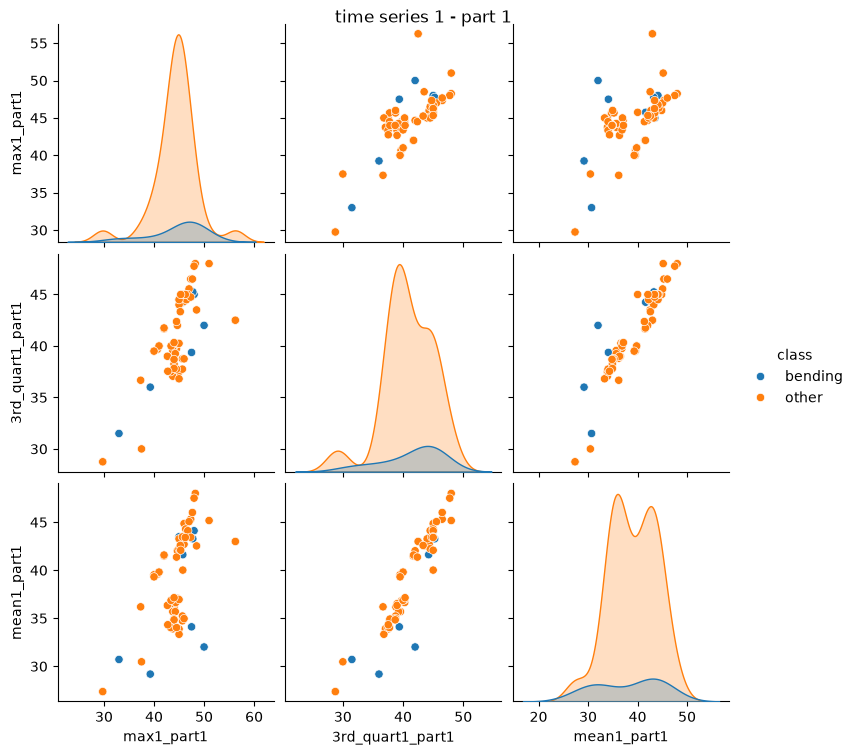

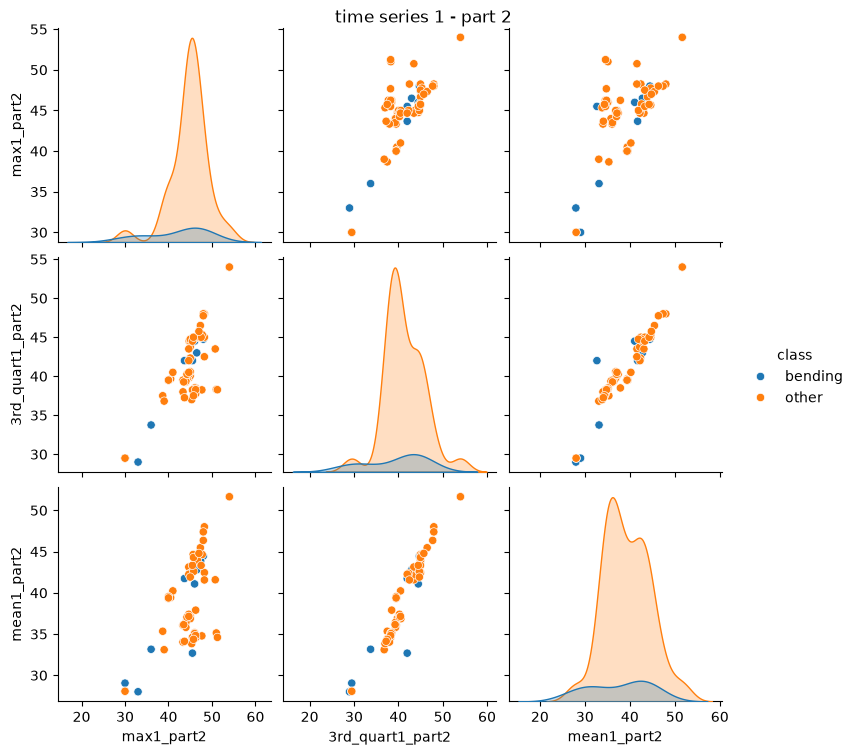

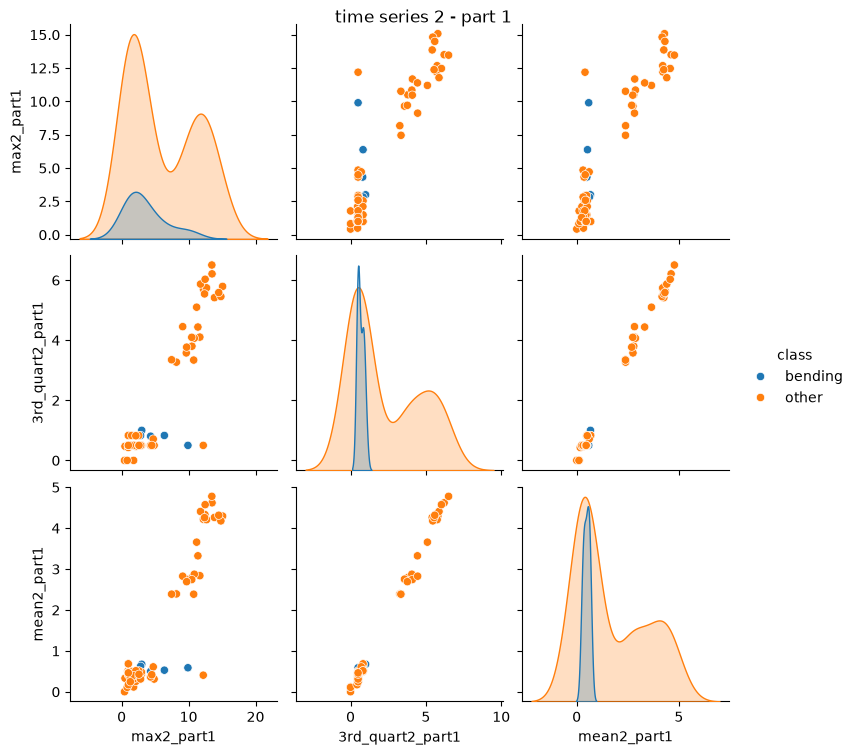

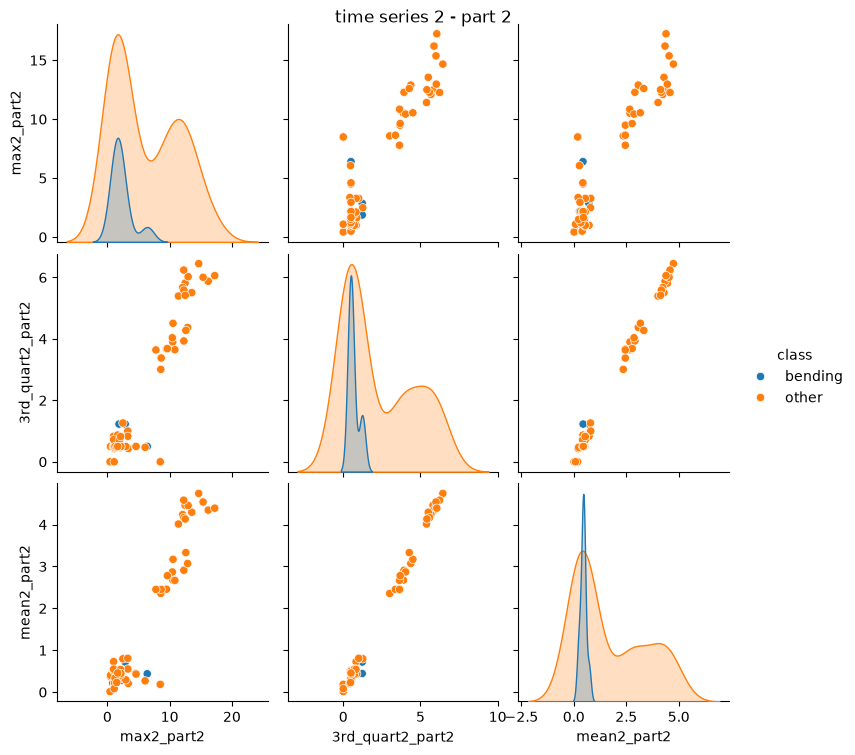

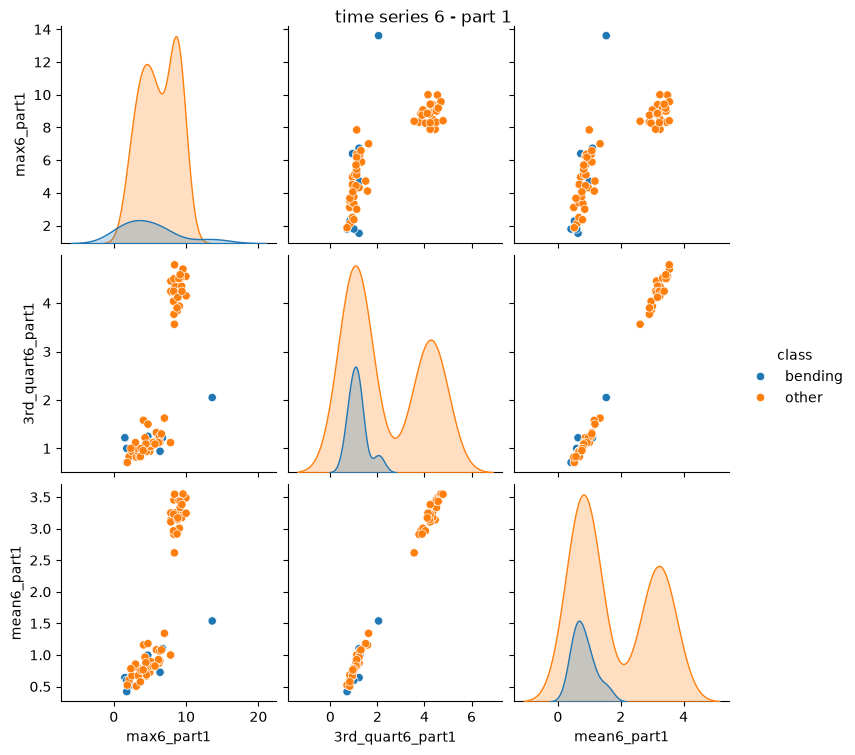

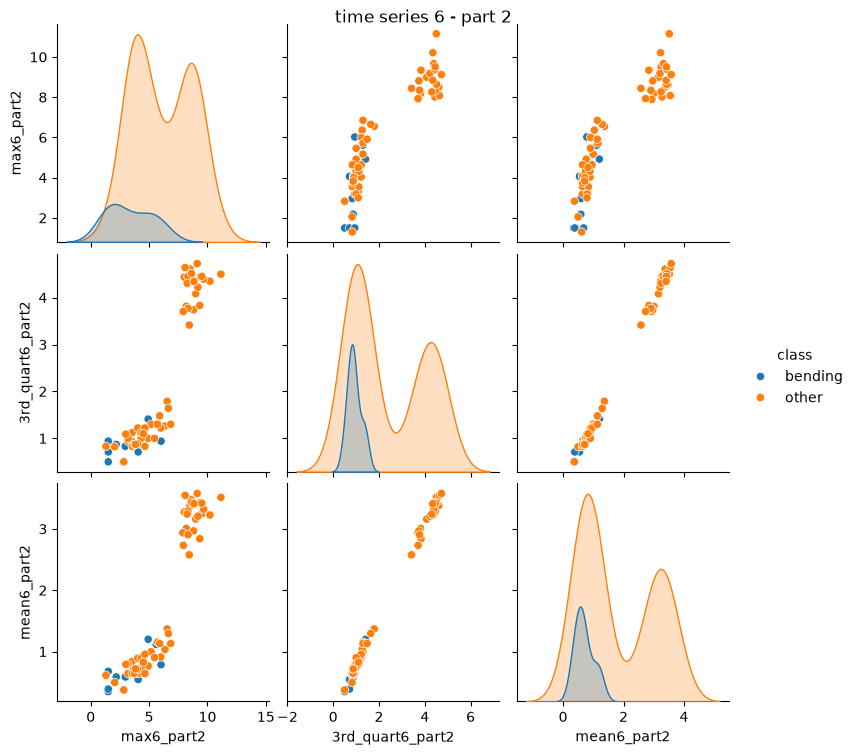

In [26]:
for ts in [1, 2, 6]:
    for part in [1, 2]:

        features = [
            f"max{ts}_part{part}",
            f"3rd_quart{ts}_part{part}",
            f"mean{ts}_part{part}"
        ]

        plot_data = scatter_split_data[
            features + ["label"]
        ].copy()

        plot_data["class"] = plot_data["label"].map({
            1: "bending",
            0: "other"
        })

        sns.pairplot(
            plot_data,
            vars=features,
            hue="class"
        )

        plt.suptitle(
            f"time series {ts} - part {part}",
            y=1
        )

        plt.show()

There is no considerable difference after breaking each time series into two equal-length time series.

#### iii. Time Series Segments

In [27]:
def extract_l_features(file_path, l):
    if "bending2/dataset4.csv" in file_path:
        data = pd.read_csv(
            file_path,
            skiprows=5,
            sep=r"\s+",
            names=[
                "time",
                "avg_rss12",
                "var_rss12",
                "avg_rss13",
                "var_rss13",
                "avg_rss23",
                "var_rss23"
            ]
        )
    else:
        data = pd.read_csv(
            file_path,
            skiprows=4,
            usecols=range(7)
        )

    features = {}

    for i, column in enumerate(time_series, start=1):
        ts = data[column]

        parts = np.array_split(ts, l)

        for j, part in enumerate(parts, start=1):
            part = pd.Series(part)

            features[f"min{i}_part{j}"] = part.min()
            features[f"max{i}_part{j}"] = part.max()
            features[f"mean{i}_part{j}"] = part.mean()
            features[f"median{i}_part{j}"] = part.median()
            features[f"std{i}_part{j}"] = part.std()
            features[f"1st_quart{i}_part{j}"] = part.quantile(0.25)
            features[f"3rd_quart{i}_part{j}"] = part.quantile(0.75)

    return features

In [28]:
p_values = range(1, 11)

cv_results = []

y = np.array(train_labels)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=5
)

for l in range(1, 21):

    print("l =", l)
    
    train_l_features = []

    for file in train_set:
        features = extract_l_features(file, l)
        train_l_features.append(features)

    X = pd.DataFrame(train_l_features)

    for p in p_values:

        cv_scores = []

        for train_index, val_index in skf.split(X, y):

            X_train = X.iloc[train_index]
            X_val = X.iloc[val_index]

            y_train = y[train_index]
            y_val = y[val_index]

            model = LogisticRegression(
                C=np.inf,
                max_iter=1000
            )

            rfe = RFE(
                model,
                n_features_to_select=p,
                step=10
            )

            rfe = rfe.fit(X_train, y_train)

            X_train_selected = rfe.transform(X_train)
            X_val_selected = rfe.transform(X_val)

            model.fit(X_train_selected, y_train)

            y_pred = model.predict(X_val_selected)

            accuracy = accuracy_score(y_val, y_pred)
            cv_scores.append(accuracy)

        mean_accuracy = np.mean(cv_scores)

        cv_results.append({
            "l": l,
            "p": p,
            "mean cv accuracy": mean_accuracy
        })

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20


In [29]:
cv_results_df = pd.DataFrame(cv_results)

cv_results_df.head()

best_result = cv_results_df.loc[
    cv_results_df["mean cv accuracy"].idxmax()
]

best_result

l                   1.0
p                   3.0
mean cv accuracy    1.0
Name: 2, dtype: float64

In [30]:
best_l = 1
best_p = 3

train_best_features = []

for file in train_set:
    features = extract_l_features(file, best_l)
    train_best_features.append(features)

X_best = pd.DataFrame(train_best_features)
y = np.array(train_labels)

In [31]:
model = LogisticRegression(
    C=np.inf,
    max_iter=1000
)

rfe = RFE(
    model,
    n_features_to_select=best_p
)

rfe = rfe.fit(X_best, y)

selected_features = X_best.columns[rfe.support_]

selected_features

Index(['3rd_quart1_part1', 'max5_part1', '1st_quart5_part1'], dtype='str')

In [32]:
X_pvalue = X_best[selected_features]

X_pvalue = sm.add_constant(X_pvalue)

logit_model = sm.Logit(y, X_pvalue)
logit_result = logit_model.fit()

print(logit_result.summary())

         Current function value: 8.338452
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  -20.53
Time:                        14:57:53   Log-Likelihood:                -575.35
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                     1.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -111.7970    131.081     -0.853      0.394    -368.711     145.117
3rd_quart1_part1    -2.4299      2.508     -0.9

/opt/anaconda3/lib/python3.14/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [33]:
X_best_selected = rfe.transform(X_best)

final_model = LogisticRegression(
    C=np.inf,
    max_iter=1000
).fit(X_best_selected, y)

The wrong way is to perform RFE feature selection using all 69 training instances first, and then divide the 69 instances into 5 folds for cross-validation. In this case, the validation fold has already participated in the feature selection process, which causes data leakage and may make the cross-validation performance look better than it actually is.
The right way is to first divide the training data into 5 folds. In each iteration, 4 folds are used for training and 1 fold is used for validation. RFE feature selection is performed using only the 4 training folds. The selected features are then used to fit the logistic regression model, and the remaining validation fold is used to evaluate the model.

#### iv. Confusion Matrix

In [34]:
y_train_pred = final_model.predict(X_best_selected)

cm = confusion_matrix(y, y_train_pred)

print(cm)

[[60  0]
 [ 0  9]]


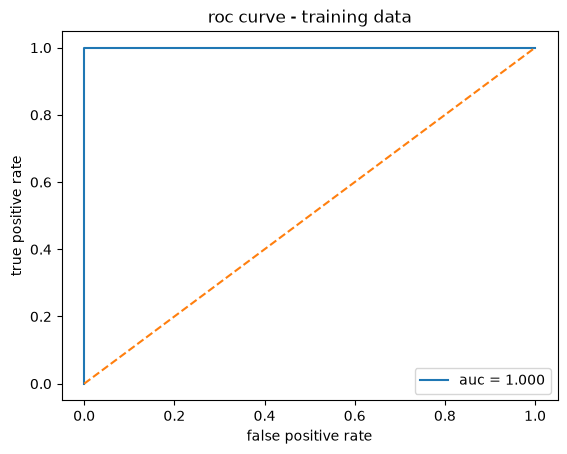

In [35]:
y_train_prob = final_model.predict_proba(X_best_selected)[:, 1]

fpr, tpr, thresholds = roc_curve(y, y_train_prob)

auc = roc_auc_score(y, y_train_prob)

plt.plot(fpr, tpr, label=f"auc = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("roc curve - training data")
plt.legend()

plt.show()

In [36]:
results_table = pd.DataFrame({
    "coefficient": logit_result.params,
    "p-value": logit_result.pvalues
})

results_table

,coefficient,p-value
const,-111.796990,0.393723
3rd_quart1_part1,-2.429936,0.332699
max5_part1,14.590409,0.341320
1st_quart5_part1,-11.275491,0.345493


#### v. Test Classifier

In [37]:
test_labels = []

for file in test_set:
    if "bending1" in file or "bending2" in file:
        test_labels.append(1)
    else:
        test_labels.append(0)

print("number of test instances:", len(test_labels))
print("bending:", sum(test_labels))
print("other:", len(test_labels) - sum(test_labels))

number of test instances: 19
bending: 4
other: 15


In [38]:
test_features = []

for file in test_set:
    features = extract_l_features(file, best_l)
    test_features.append(features)

X_test = pd.DataFrame(test_features)

print(X_test.shape)

X_test_selected = X_test[selected_features]
print(X_test_selected.shape)
X_test_selected.head()

(19, 42)
(19, 3)


,3rd_quart1_part1,max5_part1,1st_quart5_part1
0,42.00,38.25,33.00
1,43.67,38.50,32.00
2,26.50,30.00,20.50
3,30.00,33.00,15.00
4,40.25,25.50,17.95


In [39]:
y_test = np.array(test_labels)

y_test_pred = final_model.predict(X_test_selected)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("test accuracy:", test_accuracy)
print("cross-validation accuracy:", best_result["mean cv accuracy"])

test accuracy: 1.0
cross-validation accuracy: 1.0


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


#### vi. Separation

Yes. The classes seem to be well-separated because both the false positive and false negative values in the confusion matrix are zero.

#### vii. Imbalance

Yes. It is imbalanced because there are 60 instances of other activities but only 9 instances of bending.

In [40]:
np.random.seed(5)

bending_index = np.where(y == 1)[0]
other_index = np.where(y == 0)[0]

sampled_other_index = np.random.choice(
    other_index,
    size=len(bending_index),
    replace=False
)

case_control_index = np.concatenate([
    bending_index,
    sampled_other_index
])

X_case_control = X_best_selected[case_control_index]
y_case_control = y[case_control_index]

print("bending:", sum(y_case_control == 1))
print("other:", sum(y_case_control == 0))

bending: 9
other: 9


In [41]:
case_control_model = LogisticRegression(
    C=np.inf,
    max_iter=1000
).fit(X_case_control, y_case_control)

original_ratio = 9 / 60
sampled_ratio = 9 / 9

intercept_correction = np.log(original_ratio / sampled_ratio)

case_control_model.intercept_[0] += intercept_correction

y_case_control_pred = case_control_model.predict(X_best_selected)

cm_case_control = confusion_matrix(y, y_case_control_pred)

print(cm_case_control)

[[60  0]
 [ 0  9]]


auc: 1.0


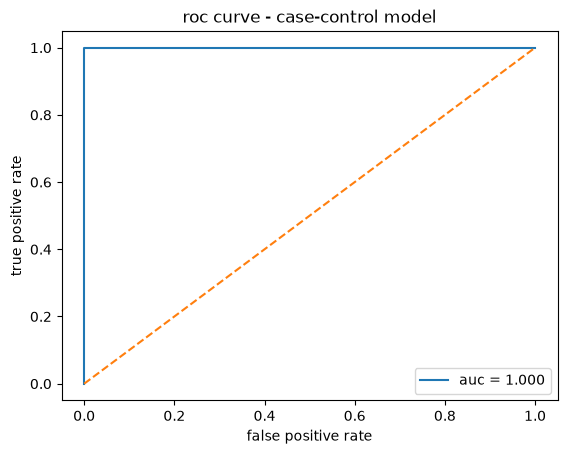

In [42]:
y_case_control_prob = case_control_model.predict_proba(
    X_best_selected
)[:, 1]

fpr_cc, tpr_cc, thresholds_cc = roc_curve(
    y, y_case_control_prob
)

auc_cc = roc_auc_score(
    y, y_case_control_prob
)

print("auc:", auc_cc)

plt.plot(fpr_cc, tpr_cc, label=f"auc = {auc_cc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("roc curve - case-control model")
plt.legend()

plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [43]:
C_values = [0.01, 0.1, 1, 10, 100]

l1_cv_results = []

y = np.array(train_labels)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=5
)

for l in range(1, 21):

    print("l =", l)

    train_l_features = []

    for file in train_set:
        features = extract_l_features(file, l)
        train_l_features.append(features)

    X = pd.DataFrame(train_l_features)

    for C in C_values:

        cv_scores = []

        for train_index, val_index in skf.split(X, y):

            X_train = X.iloc[train_index]
            X_val = X.iloc[val_index]

            y_train = y[train_index]
            y_val = y[val_index]

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(
                l1_ratio=1,
                C=C,
                solver="liblinear",
                max_iter=1000
            )

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            accuracy = accuracy_score(y_val, y_pred)
            cv_scores.append(accuracy)

        mean_accuracy = np.mean(cv_scores)

        l1_cv_results.append({
            "l": l,
            "C": C,
            "mean cv accuracy": mean_accuracy
        })

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20


In [44]:
l1_cv_results_df = pd.DataFrame(l1_cv_results)

best_l1_result = l1_cv_results_df.loc[
    l1_cv_results_df["mean cv accuracy"].idxmax()
]

best_l1_result

l                   1.000000
C                   1.000000
mean cv accuracy    0.971429
Name: 2, dtype: float64

In [45]:
best_l = 1
best_C = 1

train_l1_features = []

for file in train_set:
    features = extract_l_features(file, best_l)
    train_l1_features.append(features)

X_l1 = pd.DataFrame(train_l1_features)
y = np.array(train_labels)

l1_scaler = StandardScaler()

X_l1_scaled = l1_scaler.fit_transform(X_l1)

In [46]:
final_l1_model = LogisticRegression(
    l1_ratio=1,
    C=best_C,
    solver="liblinear",
    max_iter=1000
).fit(X_l1_scaled, y)

l1_coefficients = pd.Series(
    final_l1_model.coef_[0],
    index=X_l1.columns
)

selected_l1_features = l1_coefficients[
    l1_coefficients != 0
]

print("number of selected features:", len(selected_l1_features))
selected_l1_features

number of selected features: 7


3rd_quart1_part1   -0.568168
1st_quart3_part1   -0.020599
1st_quart4_part1   -0.124092
min5_part1          1.100991
max5_part1          1.738847
median6_part1      -0.188500
1st_quart6_part1   -0.604845
dtype: float64

#### ii. Comparison

Variable selection performs better because its cross-validation accuracy of 1.0 is higher than the accuracy of 0.9714 for L1-penalized logistic regression.
L1-penalized logistic regression is easier to implement because L1 regularization shrinks some coefficients to zero and automatically performs variable selection, without requiring RFE or p-value-based feature selection.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [47]:
train_all_labels = []

for file in train_set:
    for activity in activities:
        if f"/{activity}/" in file:
            train_all_labels.append(activity)
            break


test_all_labels = []

for file in test_set:
    for activity in activities:
        if f"/{activity}/" in file:
            test_all_labels.append(activity)
            break

print("number of training instances:", len(train_all_labels))
print(pd.Series(train_all_labels).value_counts())

print("\nnumber of test instances:", len(test_all_labels))
print(pd.Series(test_all_labels).value_counts())

number of training instances: 69
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

number of test instances: 19
cycling     3
lying       3
sitting     3
standing    3
walking     3
bending1    2
bending2    2
Name: count, dtype: int64


In [48]:
all_cv_results = []

y_all = np.array(train_all_labels)

skf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=5
)

for l in range(1, 21):

    print("l =", l)

    train_l_features = []

    for file in train_set:
        features = extract_l_features(file, l)
        train_l_features.append(features)

    X = pd.DataFrame(train_l_features)

    for C in C_values:

        cv_scores = []

        for train_index, val_index in skf.split(X, y_all):

            X_train = X.iloc[train_index]
            X_val = X.iloc[val_index]

            y_train = y_all[train_index]
            y_val = y_all[val_index]

            scaler = StandardScaler()

            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)

            model = LogisticRegression(
                l1_ratio=1,
                C=C,
                solver="saga",
                max_iter=10000,
                tol=1e-3
            )

            model.fit(X_train_scaled, y_train)

            y_pred = model.predict(X_val_scaled)

            accuracy = accuracy_score(y_val, y_pred)
            cv_scores.append(accuracy)

        mean_accuracy = np.mean(cv_scores)

        all_cv_results.append({
            "l": l,
            "C": C,
            "mean cv accuracy": mean_accuracy
        })

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20


In [49]:
all_cv_results_df = pd.DataFrame(all_cv_results)

best_all_result = all_cv_results_df.loc[
    all_cv_results_df["mean cv accuracy"].idxmax()
]

best_all_result

l                    1.000000
C                   10.000000
mean cv accuracy     0.913399
Name: 3, dtype: float64

In [50]:
best_l_all = 1
best_C_all = 10

train_all_features = []

for file in train_set:
    features = extract_l_features(file, best_l_all)
    train_all_features.append(features)

X_train_all = pd.DataFrame(train_all_features)


test_all_features = []

for file in test_set:
    features = extract_l_features(file, best_l_all)
    test_all_features.append(features)

X_test_all = pd.DataFrame(test_all_features)

y_train_all = np.array(train_all_labels)
y_test_all = np.array(test_all_labels)

In [51]:
all_scaler = StandardScaler()

X_train_all_scaled = all_scaler.fit_transform(X_train_all)
X_test_all_scaled = all_scaler.transform(X_test_all)


final_all_model = LogisticRegression(
    l1_ratio=1,
    C=best_C_all,
    solver="saga",
    max_iter=20000,
    tol=1e-3
).fit(X_train_all_scaled, y_train_all)


y_test_all_pred = final_all_model.predict(X_test_all_scaled)

test_accuracy_all = accuracy_score(
    y_test_all,
    y_test_all_pred
)

test_error_all = 1 - test_accuracy_all

print("test accuracy:", test_accuracy_all)
print("test error:", test_error_all)

test accuracy: 0.8947368421052632
test error: 0.10526315789473684


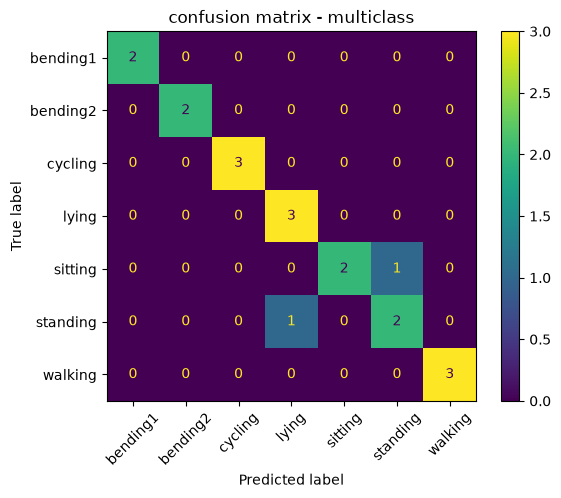

In [52]:
cm_all = confusion_matrix(
    y_test_all,
    y_test_all_pred,
    labels=activities
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_all,
    display_labels=activities
)

disp.plot()
plt.title("confusion matrix - multiclass")
plt.xticks(rotation=45)
plt.show()

In [53]:
y_test_all_prob = final_all_model.predict_proba(X_test_all_scaled)

roc_data = pd.DataFrame(
    y_test_all_prob,
    columns=final_all_model.classes_
)

roc_data["actual"] = y_test_all

roc_data.head()

,bending1,bending2,cycling,lying,sitting,standing,walking,actual
0,0.999877,0.000032,8.905459e-07,2.806137e-15,0.000091,2.729320e-09,7.393497e-09,bending1
1,0.999915,0.000006,1.154039e-06,4.891468e-15,0.000077,1.473551e-08,1.199984e-08,bending1
2,0.000345,0.998470,6.478723e-06,2.098540e-10,0.001178,8.035122e-10,7.718089e-07,bending2
3,0.000050,0.991224,2.296840e-03,9.689059e-10,0.006429,8.820479e-08,1.559789e-07,bending2
4,0.005321,0.003326,9.847750e-01,3.679460e-06,0.000316,2.408144e-04,6.017214e-03,cycling


In [54]:
%load_ext rpy2.ipython

In [55]:
%%R

library(pROC)

Type 'citation("pROC")' for a citation.

次のパッケージを付け加えます: ‘pROC’

以下のオブジェクトは ‘package:stats’ からマスクされています:

    cov, smooth, var



In [56]:
%%R -i roc_data

head(roc_data)

      bending1     bending2      cycling        lying      sitting     standing
0 9.998769e-01 3.160796e-05 8.905459e-07 2.806137e-15 9.062204e-05 2.729320e-09
1 9.999152e-01 6.414793e-06 1.154039e-06 4.891468e-15 7.718549e-05 1.473551e-08
2 3.447634e-04 9.984704e-01 6.478723e-06 2.098540e-10 1.177557e-03 8.035122e-10
3 4.985161e-05 9.912238e-01 2.296840e-03 9.689059e-10 6.429280e-03 8.820479e-08
4 5.320697e-03 3.326259e-03 9.847750e-01 3.679460e-06 3.163547e-04 2.408144e-04
5 1.048612e-02 2.843008e-03 9.788513e-01 5.598259e-06 7.826650e-04 2.490225e-04
       walking   actual
0 7.393497e-09 bending1
1 1.199984e-08 bending1
2 7.718089e-07 bending2
3 1.559789e-07 bending2
4 6.017214e-03  cycling
5 6.782310e-03  cycling


In [57]:
%%R

multi_roc <- multiclass.roc(
    roc_data$actual,
    as.matrix(roc_data[, 1:7])
)

multi_roc


Call:
multiclass.roc.default(response = roc_data$actual, predictor = as.matrix(roc_data[,     1:7]))

Data: multivariate predictor as.matrix(roc_data[, 1:7]) with 7 levels of roc_data$actual: bending1, bending2, cycling, lying, sitting, standing, walking.
Multi-class area under the curve: 0.9947


In [58]:
%%R

classes <- c(
    "bending1", "bending2", "cycling",
    "lying", "sitting", "standing", "walking"
)

roc_list <- list()

for (activity in classes) {
    
    actual_binary <- ifelse(
        roc_data$actual == activity,
        1,
        0
    )
    
    roc_list[[activity]] <- roc(
        actual_binary,
        roc_data[[activity]],
        quiet = TRUE
    )
}

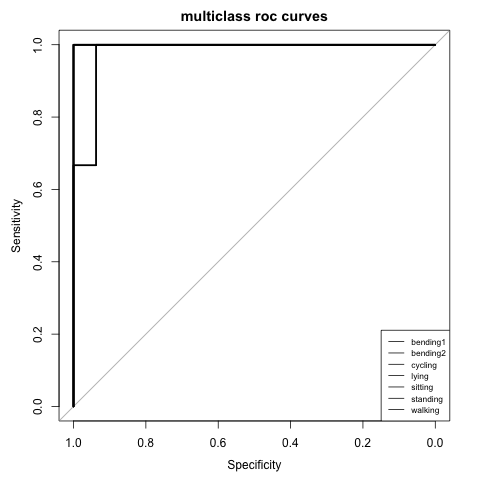

In [59]:
%%R

plot(
    roc_list[[1]],
    main = "multiclass roc curves"
)

for (i in 2:length(roc_list)) {
    plot(
        roc_list[[i]],
        add = TRUE
    )
}

legend(
    "bottomright",
    legend = classes,
    lty = 1,
    cex = 0.7
)

#### ii. Naive Bayes

In [60]:
gnb_cv_results = []

y_all = np.array(train_all_labels)

skf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=5
)

for l in range(1, 21):

    print("l =", l, flush=True)

    train_l_features = []

    for file in train_set:
        features = extract_l_features(file, l)
        train_l_features.append(features)

    X = pd.DataFrame(train_l_features)

    cv_scores = []

    for train_index, val_index in skf.split(X, y_all):

        X_train = X.iloc[train_index]
        X_val = X.iloc[val_index]

        y_train = y_all[train_index]
        y_val = y_all[val_index]

        model = GaussianNB()
        model.fit(X_train, y_train)

        y_pred = model.predict(X_val)

        accuracy = accuracy_score(y_val, y_pred)
        cv_scores.append(accuracy)

    mean_accuracy = np.mean(cv_scores)

    gnb_cv_results.append({
        "l": l,
        "mean cv accuracy": mean_accuracy
    })

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20


In [61]:
gnb_cv_results_df = pd.DataFrame(gnb_cv_results)

best_gnb_result = gnb_cv_results_df.loc[
    gnb_cv_results_df["mean cv accuracy"].idxmax()
]

best_gnb_result

l                   2.000000
mean cv accuracy    0.841503
Name: 1, dtype: float64

In [62]:
best_l_gnb = 2

train_gnb_features = []

for file in train_set:
    features = extract_l_features(file, best_l_gnb)
    train_gnb_features.append(features)

X_train_gnb = pd.DataFrame(train_gnb_features)


test_gnb_features = []

for file in test_set:
    features = extract_l_features(file, best_l_gnb)
    test_gnb_features.append(features)

X_test_gnb = pd.DataFrame(test_gnb_features)


gnb_model = GaussianNB()

gnb_model.fit(X_train_gnb, y_train_all)

y_test_gnb_pred = gnb_model.predict(X_test_gnb)

gnb_test_accuracy = accuracy_score(
    y_test_all,
    y_test_gnb_pred
)

gnb_test_error = 1 - gnb_test_accuracy

print("test accuracy:", gnb_test_accuracy)
print("test error:", gnb_test_error)

test accuracy: 0.631578947368421
test error: 0.368421052631579


In [63]:
mnb_cv_results = []

y_all = np.array(train_all_labels)

skf = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=5
)

for l in range(1, 21):

    print("l =", l, flush=True)

    train_l_features = []

    for file in train_set:
        features = extract_l_features(file, l)
        train_l_features.append(features)

    X = pd.DataFrame(train_l_features)

    cv_scores = []

    for train_index, val_index in skf.split(X, y_all):

        X_train = X.iloc[train_index]
        X_val = X.iloc[val_index]

        y_train = y_all[train_index]
        y_val = y_all[val_index]

        model = MultinomialNB()

        model.fit(X_train, y_train)

        y_pred = model.predict(X_val)

        accuracy = accuracy_score(y_val, y_pred)
        cv_scores.append(accuracy)

    mean_accuracy = np.mean(cv_scores)

    mnb_cv_results.append({
        "l": l,
        "mean cv accuracy": mean_accuracy
    })

l = 1
l = 2
l = 3
l = 4
l = 5
l = 6
l = 7
l = 8
l = 9
l = 10
l = 11
l = 12
l = 13
l = 14
l = 15
l = 16
l = 17
l = 18
l = 19
l = 20


In [64]:
mnb_cv_results_df = pd.DataFrame(mnb_cv_results)

best_mnb_result = mnb_cv_results_df.loc[
    mnb_cv_results_df["mean cv accuracy"].idxmax()
]

best_mnb_result

l                   1.000000
mean cv accuracy    0.870098
Name: 0, dtype: float64

In [65]:
best_l_mnb = 1

train_mnb_features = []

for file in train_set:
    features = extract_l_features(file, best_l_mnb)
    train_mnb_features.append(features)

X_train_mnb = pd.DataFrame(train_mnb_features)


test_mnb_features = []

for file in test_set:
    features = extract_l_features(file, best_l_mnb)
    test_mnb_features.append(features)

X_test_mnb = pd.DataFrame(test_mnb_features)


mnb_model = MultinomialNB()

mnb_model.fit(X_train_mnb, y_train_all)

y_test_mnb_pred = mnb_model.predict(X_test_mnb)

mnb_test_accuracy = accuracy_score(
    y_test_all,
    y_test_mnb_pred
)

mnb_test_error = 1 - mnb_test_accuracy

print("test accuracy:", mnb_test_accuracy)
print("test error:", mnb_test_error)

test accuracy: 0.8947368421052632
test error: 0.10526315789473684


Multinomial Naive Bayes performs better than Gaussian Naive Bayes because it has a higher cross-validation accuracy and a lower test error.

#### ii. Comparison

L1-penalized multinomial logistic regression performs better for multi-class classification in this problem. It has the highest cross-validation accuracy (0.9134) and the same lowest test error (0.1053) as Multinomial Naive Bayes.

## 3. ISLR 4.8.3

For class k, we have

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

Therefore, the density function for class k is

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

By Bayes' theorem,

$$
P(Y=k \mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}.
$$

The Bayes classifier assigns the observation to the class with the largest posterior probability.

Since the denominator is the same for all classes, we only need to compare

$$
\pi_k f_k(x).
$$

Therefore, the Bayes classifier assigns the observation to the class that maximizes

$$
\pi_k f_k(x).
$$

Substituting the normal density into the expression, we obtain

$$
\pi_k f_k(x)
=
\pi_k
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Taking the logarithm and simplifying,

$$
\log[\pi_k f_k(x)]
=
\log\pi_k
-\log(\sqrt{2\pi}\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Since

$$
\log(\sqrt{2\pi}\sigma_k)
=
\log\sqrt{2\pi}
+
\log\sigma_k,
$$

we have

$$
\log[\pi_k f_k(x)]
=
\log\pi_k
-\log\sqrt{2\pi}
-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

The discriminant function for class k is

$$
\delta_k(x)
=
\log\pi_k
-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term,

$$
(x-\mu_k)^2
=
x^2-2x\mu_k+\mu_k^2.
$$

Substituting this into the discriminant function gives

$$
\delta_k(x)
=
\log\pi_k
-\log\sigma_k
-\frac{x^2-2x\mu_k+\mu_k^2}{2\sigma_k^2}.
$$


Simplifying the expression,

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k
+\log\pi_k.
$$

In QDA, the variances are class-specific.Therefore, the coefficient of the quadratic term

$$
-\frac{x^2}{2\sigma_k^2}
$$

can be different for different classes, so the quadratic term does not cancel.

Hence, the decision boundary contains an \(x^2\) term and has the form

$$
Ax^2+Bx+C=0.
$$

Therefore, the Bayes classifier is quadratic in x, rather than linear.

## 4. ISLR 4.8.7

Yes = issued a dividend
No  = did not issue a dividend

We are given

$$
\mu_{\text{Yes}}=10,
\qquad
\mu_{\text{No}}=0,
$$

and

$$
\sigma^2=36,
\qquad
\sigma=6.
$$

The prior probabilities are

$$
P(\text{Yes})=0.8
$$

and

$$
P(\text{No})=0.2.
$$

We want to find

$$
P(\text{Yes}\mid X=4).
$$

Using the normal density function, for the Yes class,

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(
-\frac{(4-10)^2}{2(36)}
\right).
$$

Therefore,

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{72\pi}}
e^{-1/2}.
$$

For the No class,

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{2\pi(36)}}
\exp\left(
-\frac{(4-0)^2}{2(36)}
\right).
$$

Therefore,

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{72\pi}}
e^{-2/9}.
$$

Using Bayes' theorem,

$$
P(\text{Yes}\mid X=4)
=
\frac{
P(\text{Yes})f_{\text{Yes}}(4)
}{
P(\text{Yes})f_{\text{Yes}}(4)
+
P(\text{No})f_{\text{No}}(4)
}.
$$

Substituting the values,

$$
P(\text{Yes}\mid X=4)
=
\frac{
0.8e^{-1/2}
}{
0.8e^{-1/2}
+
0.2e^{-2/9}
}.
$$

Therefore,

$$
P(\text{Yes}\mid X=4)
\approx 0.752.
$$

Thus, the probability that the company will issue a dividend this year is approximately 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9